# 04 · Explainability and path to approval

A lender has to be able to tell an applicant **why** they were declined and **what would change it**.
This notebook explains the SecondLook model from notebook 03 at three levels:

1. **The whole model:** which features matter, and in which direction (SHAP).
2. **Thin-file vs others:** does the model really lean on alternative data for thin-file applicants?
3. **One applicant:** the reasons behind a single decision, and the smallest realistic changes that would get them approved.

SHAP values come straight from LightGBM (`pred_contrib=True`), the exact TreeSHAP algorithm. They are in log-odds and
add up to the model's raw score. Everything is computed on the **test** split.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))  # import secondlook from src/ (no pip install needed)

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

from secondlook.config import FIGURES_DIR, MODELS_DIR, TARGET_COL
from secondlook.explain import LEVERS, apply_lever, describe, path_to_approval, score, shap_values, top_reasons
from secondlook.features import load_features
from secondlook.modeling import ALT_FLAGS, ALT_PREFIXES, load_bundle, prepare

sns.set_theme(style="whitegrid", context="notebook")
BLUE, ORANGE = "#4C72B0", "#DD8452"

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

def is_alt(col):
    return col.startswith(ALT_PREFIXES) or col in ALT_FLAGS

In [2]:
bundle = load_bundle("secondlook_lgbm")
meta = json.loads((MODELS_DIR / "secondlook_lgbm_meta.json").read_text())
CUTOFF = meta["risk_appetite"]["cutoff"]  # 5% risk appetite, chosen on validation in notebook 03

df = prepare(load_features())
test = df[df["split"] == "test"].copy()
test["PD"] = score(bundle, test)
test["DECISION"] = np.where(test["PD"] <= CUTOFF, "Approve", "Decline")
print(f"Cutoff: approve if probability of default <= {CUTOFF:.3f}")
print(test.groupby("THIN_FILE")["DECISION"].value_counts(normalize=True).unstack().round(3))

Cutoff: approve if probability of default <= 0.158
DECISION   Approve  Decline
THIN_FILE                  
0            0.887    0.113
1            0.830    0.170


## 1. What drives the model overall?

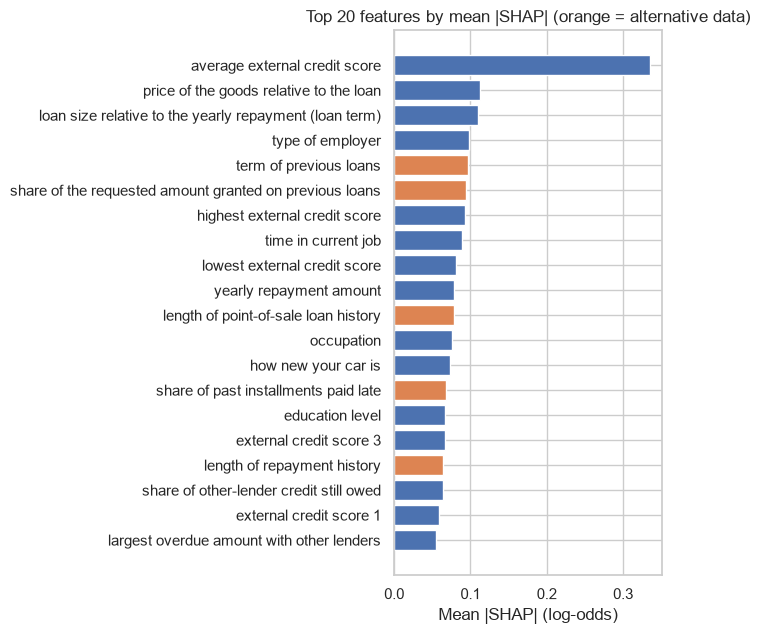

In [3]:
sample = test.sample(5000, random_state=42)
contrib, base_value = shap_values(bundle, sample)

mean_abs = contrib.abs().mean().sort_values(ascending=False)
top = mean_abs.head(20).sort_values()
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh([describe(c) for c in top.index], top.values, color=[ORANGE if is_alt(c) else BLUE for c in top.index])
ax.set(title="Top 20 features by mean |SHAP| (orange = alternative data)", xlabel="Mean |SHAP| (log-odds)")
savefig("15_shap_importance")

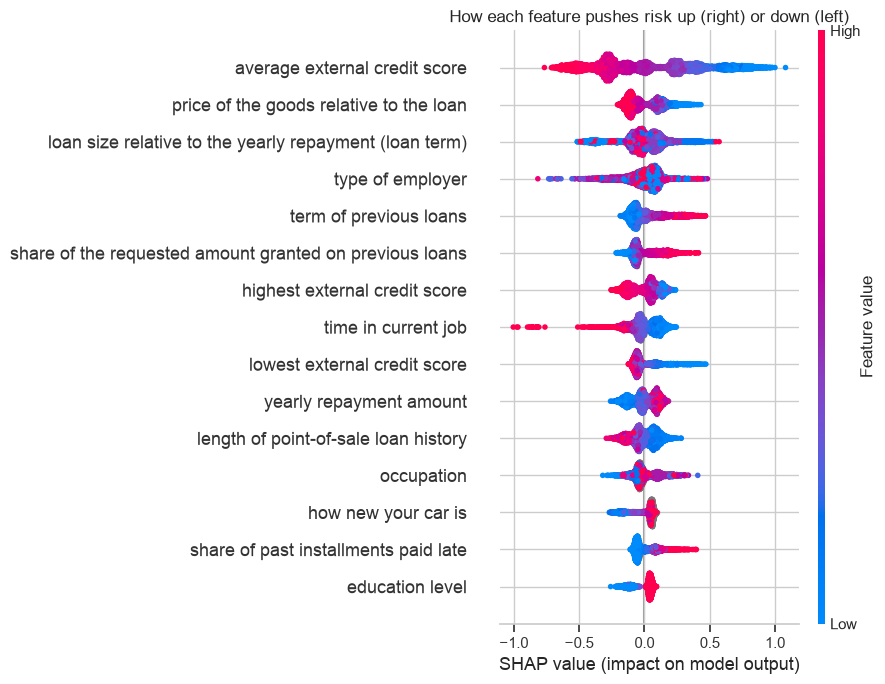

In [4]:
# Beeswarm: each dot is an applicant; position = effect on risk, colour = feature value.
cols = list(mean_abs.head(15).index)
data = sample[cols].copy()
for c in cols:
    if isinstance(data[c].dtype, pd.CategoricalDtype):
        data[c] = data[c].cat.codes.replace(-1, np.nan)
exp = shap.Explanation(values=contrib[cols].to_numpy(), base_values=np.full(len(sample), base_value),
                       data=data.to_numpy(dtype=float), feature_names=[describe(c) for c in cols])
shap.plots.beeswarm(exp, max_display=15, show=False)
plt.gcf().set_size_inches(9, 7)
plt.title("How each feature pushes risk up (right) or down (left)")
savefig("16_shap_beeswarm")

Reading the beeswarm: a **high** average external score (red dots) pushes risk **down**. Paying past installments
late, loan size relative to the yearly repayment and the share of the requested amount granted on previous loans
are the alternative-data signals visible in the top 15.

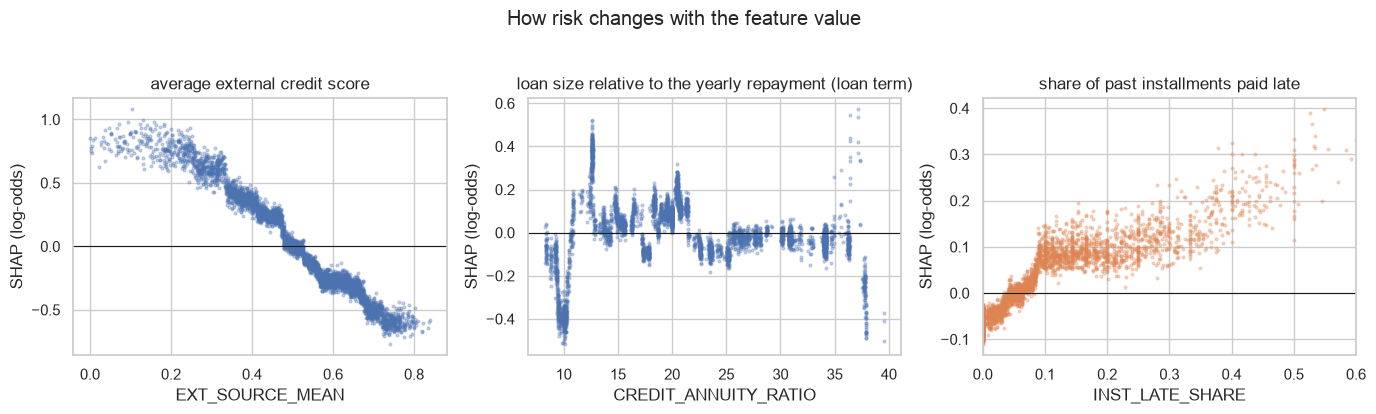

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["EXT_SOURCE_MEAN", "CREDIT_ANNUITY_RATIO", "INST_LATE_SHARE"]):
    x = sample[col]
    ax.scatter(x, contrib[col], s=4, alpha=0.3, color=ORANGE if is_alt(col) else BLUE)
    ax.axhline(0, color="k", lw=0.8)
    ax.set(title=describe(col), xlabel=col, ylabel="SHAP (log-odds)")
    if col == "INST_LATE_SHARE":
        ax.set_xlim(0, 0.6)
fig.suptitle("How risk changes with the feature value", y=1.03)
savefig("17_shap_dependence")

## 2. Does the model use alternative data more for thin-file applicants?
If SecondLook works as intended, alternative data should carry **more** of the explanation for thin-file applicants,
who have no bureau history for the model to rely on.

Has bureau history    0.229
Thin-file             0.248
dtype: float64

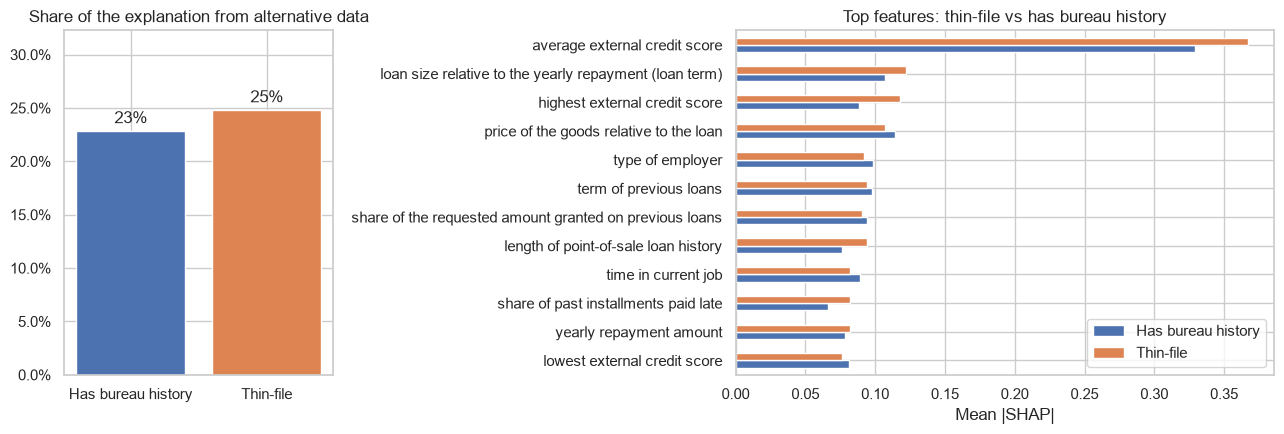

In [6]:
thin = sample["THIN_FILE"] == 1
alt_cols = [c for c in contrib.columns if is_alt(c)]
share = pd.Series({
    "Has bureau history": contrib.loc[~thin, alt_cols].abs().sum(axis=1).sum() / contrib.loc[~thin].abs().sum(axis=1).sum(),
    "Thin-file": contrib.loc[thin, alt_cols].abs().sum(axis=1).sum() / contrib.loc[thin].abs().sum(axis=1).sum(),
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 2]})
bars = axes[0].bar(share.index, share.values, color=[BLUE, ORANGE])
axes[0].bar_label(bars, labels=[f"{v:.0%}" for v in share], padding=3)
axes[0].set(title="Share of the explanation from alternative data", ylim=(0, max(share) * 1.3))
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

seg = pd.DataFrame({"Has bureau history": contrib[~thin].abs().mean(), "Thin-file": contrib[thin].abs().mean()})
seg = seg.loc[seg.max(axis=1).sort_values(ascending=False).head(12).index][::-1]
seg.index = [describe(c) for c in seg.index]
seg.plot.barh(ax=axes[1], color=[BLUE, ORANGE])
axes[1].set(title="Top features: thin-file vs has bureau history", xlabel="Mean |SHAP|")
savefig("18_shap_thin_vs_bureau")
share.round(3)

## 3. One applicant: why declined, and what would change it?
We pick a **borderline** thin-file applicant: declined, but within 5 points of the cutoff.
These are the applicants where a second look and a clear explanation matter most.

In [7]:
borderline = test[(test["PD"] > CUTOFF) & (test["PD"] <= CUTOFF + 0.05)]
print(f"Borderline declines on test: {len(borderline):,} ({len(borderline) / (test['DECISION'] == 'Decline').sum():.0%} of all declines); "
      f"{borderline['THIN_FILE'].mean():.0%} are thin-file")

# Example: a random borderline thin-file applicant who has a realistic path to approval
# (section 4 shows how often such a path exists).
candidates = borderline[borderline["THIN_FILE"] == 1].sample(frac=1, random_state=7)
applicant = next(candidates.loc[[i]] for i in candidates.index
                 if len(path_to_approval(bundle, candidates.loc[[i]], CUTOFF, max_options=1)))
c_one, base_one = shap_values(bundle, applicant)
print(f"Applicant {int(applicant['SK_ID_CURR'].iloc[0])}: probability of default {applicant['PD'].iloc[0]:.1%} "
      f"(cutoff {CUTOFF:.1%}) -> {applicant['DECISION'].iloc[0]}")

Borderline declines on test: 1,580 (28% of all declines); 20% are thin-file
Applicant 412895: probability of default 17.4% (cutoff 15.8%) -> Decline


In [8]:
def show(v):
    # Text for a feature value: category labels as-is, missing values spelled out.
    if pd.isna(v):
        return "missing"
    return v if isinstance(v, str) else round(float(v), 3)

row = applicant[bundle["columns"]].iloc[0]
data_one = np.array([show(row[c]) for c in bundle["columns"]], dtype=object)
exp_one = shap.Explanation(values=c_one.iloc[0].to_numpy(), base_values=base_one, data=data_one,
                           feature_names=[describe(c) for c in bundle["columns"]])
shap.plots.waterfall(exp_one, max_display=12, show=False)
plt.gcf().set_size_inches(9, 6)
plt.title("What moved this applicant's risk (log-odds)")
savefig("19_shap_individual")

In [9]:
reasons = top_reasons(c_one.iloc[0], applicant.iloc[0], n=4, direction="risk")
strengths = top_reasons(c_one.iloc[0], applicant.iloc[0], n=3, direction="strength")
print("Main reasons for the decline:")
for r in reasons.itertuples():
    print(f"  - {r.reason} (value: {show(r.value)})")
print("Working in the applicant's favour:")
for r in strengths.itertuples():
    print(f"  + {r.reason} (value: {show(r.value)})")

Main reasons for the decline:
  - average external credit score (value: 0.06)
  - lowest external credit score (value: 0.06)
  - highest external credit score (value: 0.06)
  - length of point-of-sale loan history (value: 8.0)
Working in the applicant's favour:
  + share of amounts due that were actually paid (value: 1.613)
  + how new your car is (value: 8.0)
  + providing document 3 (value: 0.0)


In [10]:
options = path_to_approval(bundle, applicant, CUTOFF)
print(f"Current probability of default: {applicant['PD'].iloc[0]:.1%}; needs to fall below {CUTOFF - 0.01:.1%} "
      f"(cutoff minus a 1-point safety margin)")
options[["change", "new_pd"]].style.format({"new_pd": "{:.1%}"}).hide(axis="index")

Current probability of default: 17.4%; needs to fall below 14.8% (cutoff minus a 1-point safety margin)


change,new_pd
"Choose a 50% cheaper purchase, so the loan and repayments are 50% smaller and pay 50% of the loan upfront as a bigger down payment",11.6%


## 4. Across all borderline declines
### Most common main reason

In [11]:
c_b, _ = shap_values(bundle, borderline)
main_reason = c_b.idxmax(axis=1).map(describe)
counts = main_reason.value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(counts.index, counts.values / len(borderline), color=BLUE)
ax.set(title="Main reason for borderline declines", xlabel="Share of borderline declines")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
savefig("20_borderline_reasons")

### Path to approval for borderline declines
For a random sample of 500 borderline declines, how often is there a realistic path to approval, and which changes does it involve?

**Why "longer term" is not offered by default.** The dependence plot above shows the model's response to loan term is
jagged: risk spikes at specific values of loan size / yearly repayment, which most likely correspond to particular loan
products. Changing the term would mostly move the applicant between products in the model's eyes, not change how likely
they are to repay, so suggesting it would be misleading. The search only uses borrowing less, a bigger down payment,
paying down debt and lowering card use (`explain.DEFAULT_LEVERS`).

In [12]:
paths = []
for i, (_, x) in enumerate(borderline.sample(500, random_state=0).iterrows()):
    opt = path_to_approval(bundle, borderline.loc[[x.name]], CUTOFF, max_options=1)
    paths.append({"thin": x["THIN_FILE"] == 1, "found": len(opt) > 0,
                  "lever": " + ".join(opt.loc[0, "levers"]) if len(opt) else None,
                  "size": opt.loc[0, "size"] if len(opt) else np.nan})
paths = pd.DataFrame(paths)
summary = paths.groupby("thin").agg(applicants=("found", "size"), path_found=("found", "mean"), median_change=("size", "median"))
summary.index = summary.index.map({False: "Has bureau history", True: "Thin-file"})
summary.style.format({"path_found": "{:.0%}", "median_change": "{:.0%}"})

,applicants,path_found,median_change
thin,,,
Has bureau history,394,83%,35%
Thin-file,106,68%,35%


In [13]:
lever_names = {"borrow_less": "Borrow less", "bigger_down_payment": "Bigger down payment", "longer_term": "Longer term",
               "pay_down_debt": "Pay down debt", "lower_card_use": "Lower card use"}
lv = paths["lever"].dropna().map(lambda s: " + ".join(lever_names[p] for p in s.split(" + ")))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
lv.value_counts().head(8).sort_values().plot.barh(ax=axes[0], color=ORANGE)
axes[0].set(title="Smallest path to approval: which change", xlabel="Applicants")
paths["size"].dropna().value_counts().sort_index().plot.bar(ax=axes[1], color=BLUE)
axes[1].set(title="Size of the change needed", xlabel="Change (share of amount)", ylabel="Applicants")
axes[1].set_xticklabels([f"{float(t.get_text()):.0%}" for t in axes[1].get_xticklabels()], rotation=0)
savefig("21_path_to_approval")

### Sanity check: does each lever move risk in a sensible direction?
A path to approval is only credible if the model responds sensibly. For every borderline applicant we apply each lever at
20% and measure the average change in predicted risk. Borrowing less, paying down debt and lower card use should all
**reduce** risk.

In [14]:
rows = []
X_b = borderline.copy()
for lever in LEVERS:
    mask = X_b.apply(lever.applies, axis=1)
    if mask.sum() == 0:
        continue
    before = score(bundle, X_b[mask])
    after = score(bundle, apply_lever(X_b[mask], lever.name, 0.20))
    rows.append({"lever": lever_names[lever.name], "applicants": int(mask.sum()),
                 "mean_change_pts": (after - before).mean() * 100, "share_lower_risk": (after < before).mean(),
                 "share_higher_risk": (after > before).mean()})
pd.DataFrame(rows).set_index("lever").style.format(
    {"mean_change_pts": "{:+.2f}", "share_lower_risk": "{:.0%}", "share_higher_risk": "{:.0%}"})

,applicants,mean_change_pts,share_lower_risk,share_higher_risk
lever,,,,
Borrow less,1580,-0.68,53%,6%
Bigger down payment,1580,-2.03,75%,2%
Longer term,1580,-1.67,70%,10%
Pay down debt,1025,-0.45,38%,3%
Lower card use,405,-1.67,72%,1%


## Takeaways

All numbers are on the test split, using the 5% risk-appetite cutoff from notebook 03 (approve if probability of default ≤ 15.8%).

1. **The model behaves sensibly.** Higher external scores lower risk smoothly; a larger share of installments paid late raises it. These are the shapes a credit analyst would expect.
2. **Alternative data carries about a quarter of every explanation**, slightly more for thin-file applicants (25% vs 23%). The external credit score still dominates both groups, so the thin-file gain in notebook 03 comes from many smaller alternative-data signals rather than one big one.
3. **Borderline declines are a large group.** 1,580 test applicants (28% of all declines) are within 5 points of the cutoff; 20% of them are thin-file. For 73% of them, the main reason is a low external credit score, which the applicant cannot change directly.
4. **Path to approval.** Using only realistic levers (borrow less, a bigger down payment, pay down debt, lower card use) and requiring a 1-point safety margin below the cutoff, a path exists for 83% of borderline applicants with bureau history and 68% of thin-file ones. The median change needed is 35%. Thin-file applicants have fewer levers: most have no bureau debt or credit card to pay down.
5. **Every lever moves risk the right way on average** (sanity check table), so the suggestions are consistent with the model.
6. **An explainability finding that changed the design.** The model's response to loan term is jagged, with spikes at specific values that most likely mark particular loan products. Suggesting a longer term would exploit that artefact rather than reduce real risk, so it is excluded from suggestions by default, even though it would make the numbers look better (in the first version of the model it raised path coverage to about 98%).
7. **Caveat.** A path to approval says what would change *the model's* decision, not what would cause the applicant to repay. The letters in notebook 05 phrase it that way.